In [19]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()


Saving netflix_titles.csv to netflix_titles (1).csv


In [20]:
df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [21]:
#Check the number of rows and colomuns
print(df.shape)

#display all colomuns names
print(df.columns.tolist())

#check column data types
df.info()

#check missing values
print(df.isnull().sum())

#check duplicates
print(df.duplicated().sum())

(8807, 12)
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
show_id            0
type               0
title              0
director        2634
cast             

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


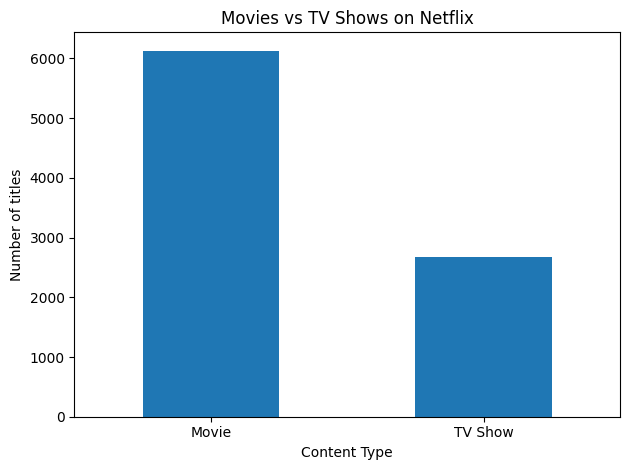

In [22]:
content_counts = df["type"].value_counts()
print(content_counts)

content_counts.plot(
    kind="bar",
    title="Movies vs TV Shows on Netflix",
    xlabel="Content Type",
    ylabel="Number of titles"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

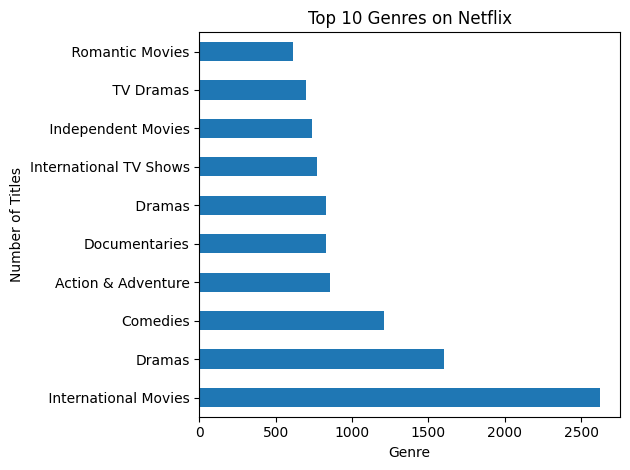

In [23]:
genres = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
)

top_genres = genres.value_counts().head(10)

top_genres.plot(
    kind="barh",
    title="Top 10 Genres on Netflix",
    xlabel="Genre",
    ylabel="Number of Titles"
)

plt.tight_layout()
plt.show()

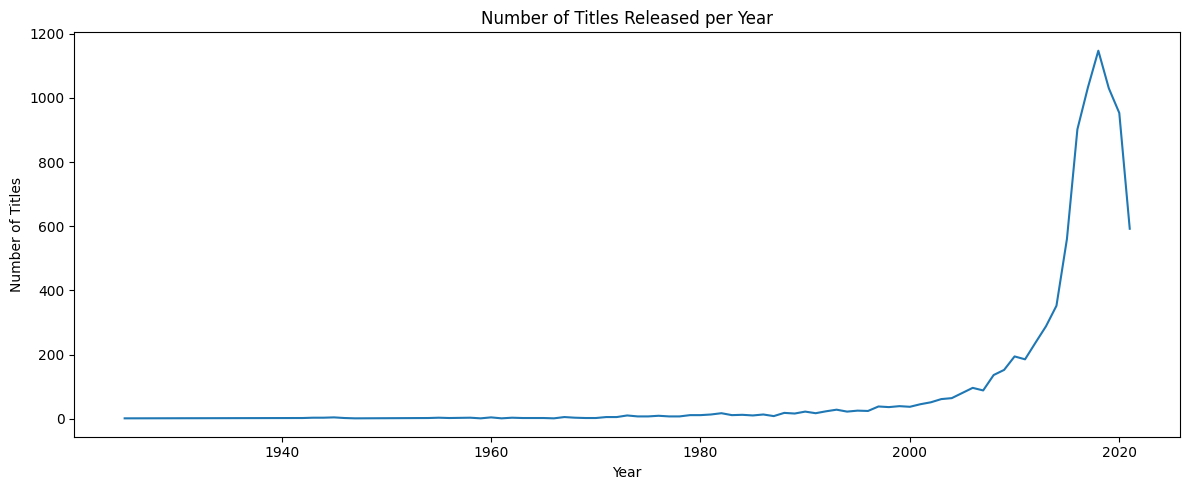

In [24]:
year_counts = df["release_year"].value_counts().sort_index()

year_counts.plot(
    figsize=(12, 5),
    title="Number of Titles Released per Year",
    xlabel="Year",
    ylabel="Number of Titles"
)

plt.tight_layout()
plt.show()


country
USA            3690
India          1046
UK              806
Canada          445
France          393
Japan           318
Spain           232
South Korea     231
Germany         226
Mexico          169
Name: count, dtype: int64


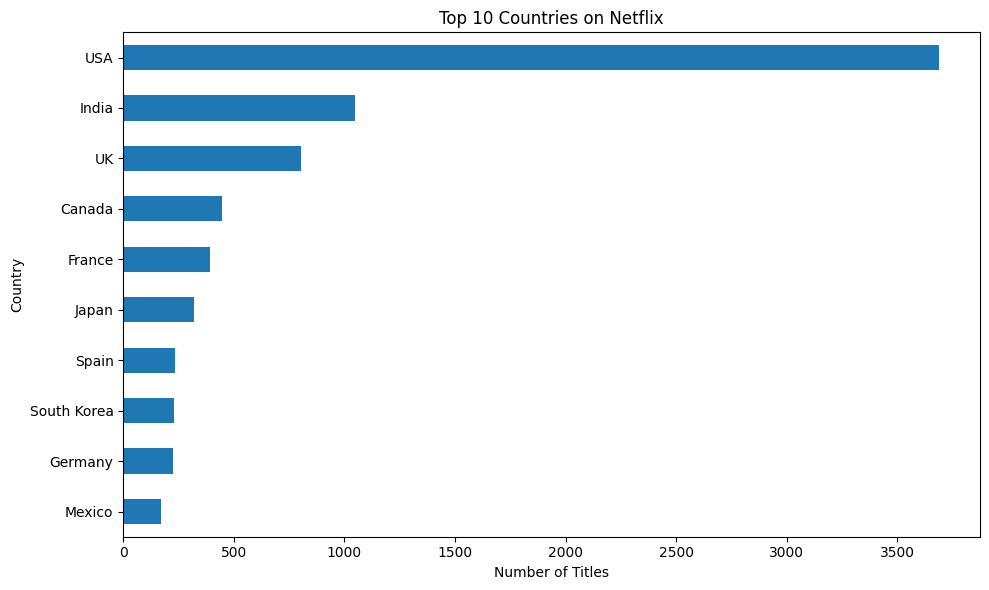

In [25]:
countries=(
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

countries=countries.replace({
    "United States": "USA",
    "United Kingdom": "UK",
})

top_countries = countries.value_counts().head(10)

print(top_countries)

top_countries.sort_values().plot(
    kind="barh",
    title="Top 10 Countries on Netflix",
    xlabel="Number of Titles",
    ylabel="Country",
    figsize=(10,6)
)

plt.tight_layout()
plt.show()


In [26]:
print("Duplicate country labels:",
top_countries.index.duplicated().any())
print(top_countries)

Duplicate country labels: False
country
USA            3690
India          1046
UK              806
Canada          445
France          393
Japan           318
Spain           232
South Korea     231
Germany         226
Mexico          169
Name: count, dtype: int64


count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


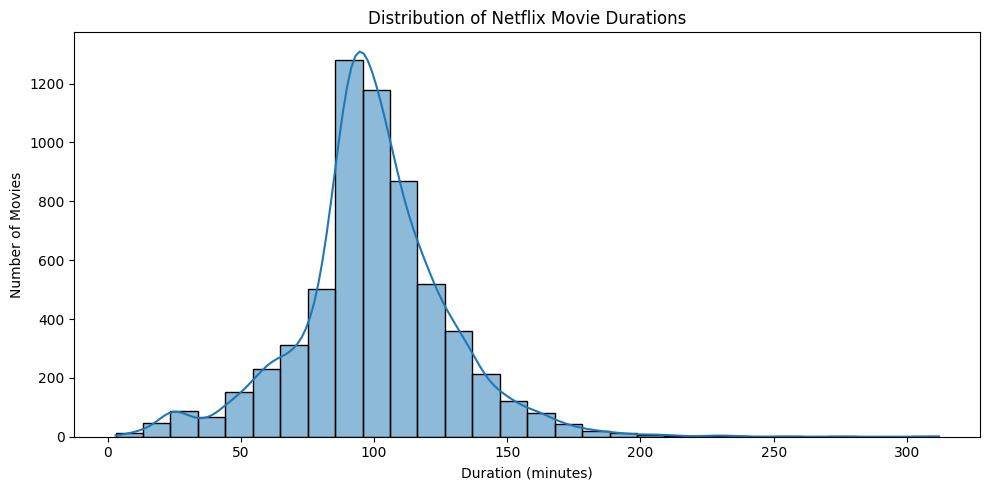

In [27]:
# Select movies only
movies = df[df["type"] == "Movie"].copy()

# Extract duration in minutes
movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Display summary statistics
print(movies["duration_minutes"].describe())

# Plot movie duration distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    movies["duration_minutes"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()


In [28]:

# Calculate key statistics
average_duration = movies["duration_minutes"].mean()
median_duration = movies["duration_minutes"].median()
shortest_movie = movies["duration_minutes"].min()
longest_movie = movies["duration_minutes"].max()

print(f"Average duration: {average_duration:.2f} minutes")
print(f"Median duration: {median_duration:.2f} minutes")
print(f"Shortest duration: {shortest_movie:.0f} minutes")
print(f"Longest duration: {longest_movie:.0f} minutes")


Average duration: 99.58 minutes
Median duration: 98.00 minutes
Shortest duration: 3 minutes
Longest duration: 312 minutes


In [29]:

# Show the 5 shortest movies
print("5 Shortest Movies:")
print(
    movies[
        ["title", "release_year", "duration", "duration_minutes"]
    ]
    .sort_values("duration_minutes")
    .head(5)
    .to_string(index=False)
)

# Show the 5 longest movies
print("\n5 Longest Movies:")
print(
    movies[
        ["title", "release_year", "duration", "duration_minutes"]
    ]
    .sort_values("duration_minutes", ascending=False)
    .head(5)
    .to_string(index=False)
)


5 Shortest Movies:
                                           title  release_year duration  duration_minutes
                                          Silent          2014    3 min               3.0
                                     Sol Levante          2020    5 min               5.0
                                Cops and Robbers          2020    8 min               8.0
                                          Canvas          2020    9 min               9.0
American Factory: A Conversation with the Obamas          2019   10 min              10.0

5 Longest Movies:
                      title  release_year duration  duration_minutes
 Black Mirror: Bandersnatch          2018  312 min             312.0
Headspace: Unwind Your Mind          2021  273 min             273.0
     The School of Mischief          1973  253 min             253.0
             No Longer kids          1979  237 min             237.0
         Lock Your Girls In          1982  233 min             233.0


Content Counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Content Percentages:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


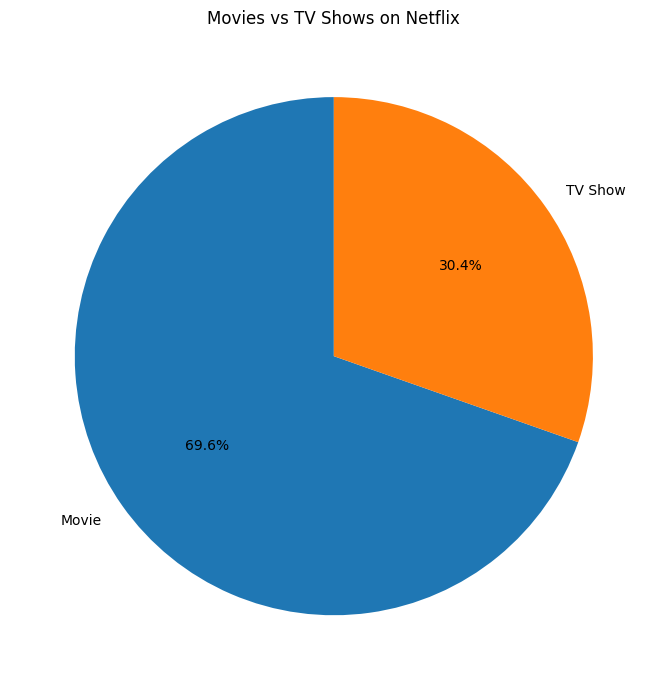

In [30]:

# Count movies and TV shows
content_counts = df["type"].value_counts()

# Calculate percentage
content_percentages = (
    df["type"].value_counts(normalize=True) * 100
)

print("Content Counts:")
print(content_counts)

print("\nContent Percentages:")
print(content_percentages.round(2))

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Movies vs TV Shows on Netflix")
plt.tight_layout()
plt.show()


In [31]:

# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

# Extract the year Netflix added each title
df["year_added"] = df["date_added"].dt.year

# Count titles added per year
yearly_additions = df["year_added"].value_counts().sort_index()

print(yearly_additions)


year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


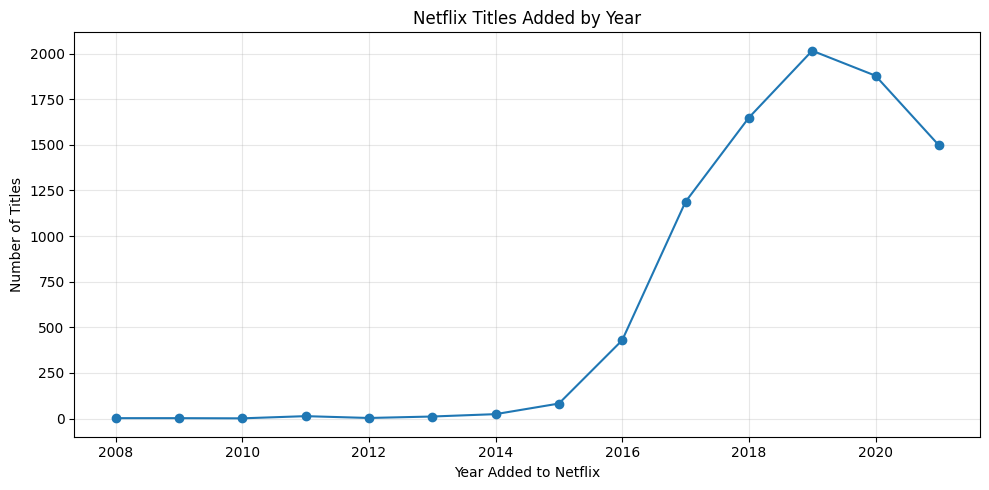

In [32]:

plt.figure(figsize=(10, 5))

yearly_additions.plot(kind="line", marker="o")

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [33]:

peak_year = yearly_additions.idxmax()
peak_count = yearly_additions.max()

print("Peak year:", peak_year)
print("Titles added:", peak_count)


Peak year: 2019.0
Titles added: 2016


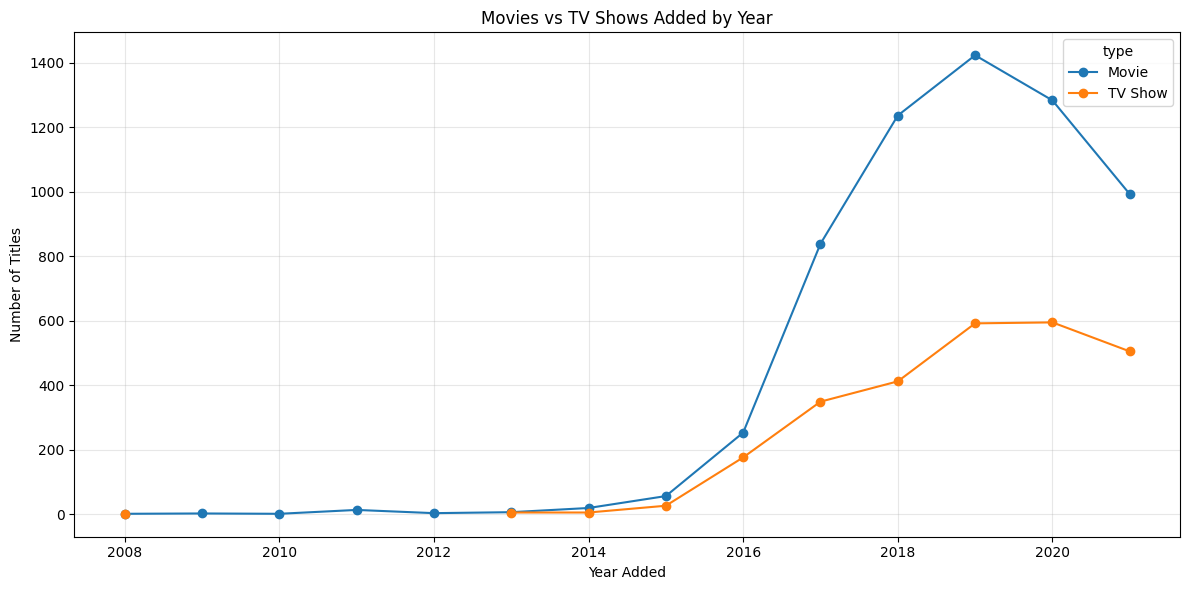

In [34]:

content_by_year = df.pivot_table(
    index="year_added",
    columns="type",
    values="title",
    aggfunc="count"
)

content_by_year.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Movies vs TV Shows Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:

# Find the peak addition year for each type
content_by_year = df.pivot_table(
    index="year_added",
    columns="type",
    values="title",
    aggfunc="count"
)

for content_type in content_by_year.columns:
    peak_year = content_by_year[content_type].idxmax()
    peak_count = content_by_year[content_type].max()

    print(f"{content_type}:")
    print(f"  Peak year: {int(peak_year)}")
    print(f"  Titles added: {int(peak_count)}")


Movie:
  Peak year: 2019
  Titles added: 1424
TV Show:
  Peak year: 2020
  Titles added: 595
